# Model 03 — Customer Lifetime Value Prediction
## 04. Final Model & Explainability — Reviewed

### Objective
Reproduce the candidate comparison, select the provisional Random Forest based on the lowest hold-out MAE, inspect its feature importance and errors, and save the model pipeline plus reproducibility metadata.

**Target:** `future_gross_purchase_value` over the fixed prediction horizon. This is a one-year future purchase-value proxy, not true lifetime value or profit.

**Important:** The current evidence is a random customer hold-out from one observation/target period. It is preliminary and does not replace temporal backtesting.

## 1. Load the processed dataset and define the reproducible split
Run Notebook 02 first. Paths are resolved relative to the model folder.

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from datetime import datetime, timezone
import platform
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance
import joblib

# Support Jupyter launched from either the notebooks/ directory or the model root.
_candidate_roots = [Path.cwd(), *Path.cwd().parents]
MODEL_ROOT = next(
    (root for root in _candidate_roots
     if (root / "data" / "processed" / "clv_customer_features_and_targets.csv").exists()),
    None,
)
if MODEL_ROOT is None:
    expected = Path.cwd() / "data" / "processed" / "clv_customer_features_and_targets.csv"
    raise FileNotFoundError(
        "Processed CLV dataset not found. Run Notebook 02's final export cell, "
        "then launch this notebook from the Model 03 folder or its notebooks folder. "
        f"Checked current directory and parent folders; expected file like: {expected}"
    )
DATASET_PATH = MODEL_ROOT / "data" / "processed" / "clv_customer_features_and_targets.csv"

# Model binaries and metadata belong in the backend's dedicated model registry folder.
# Expected project layout:
# <project-root>/ml/model_03_customer_lifetime_value/
# <project-root>/backend/models/customer_lifetime_value/
PROJECT_ROOT = MODEL_ROOT.parents[1]
BACKEND_MODEL_DIR = PROJECT_ROOT / "backend" / "models" / "customer_lifetime_value"
REPORT_DIR = MODEL_ROOT / "reports"

if not (PROJECT_ROOT / "backend").is_dir():
    raise FileNotFoundError(
        f"Could not locate the project's backend folder at {PROJECT_ROOT / 'backend'}. "
        "Check that the notebook is inside ml/model_03_customer_lifetime_value/notebooks."
    )

data = pd.read_csv(DATASET_PATH)
TARGET = "future_gross_purchase_value"
feature_columns = [
    "observation_invoice_count",
    "observation_total_value",
    "observation_average_invoice_value",
    "observation_median_invoice_value",
    "observation_total_quantity",
    "observation_product_line_count",
    "recency_days",
    "customer_tenure_days",
    "average_days_between_observed_purchases",
]
required = [TARGET, *feature_columns]
missing = [c for c in required if c not in data.columns]
if missing:
    raise KeyError(f"Missing required columns: {missing}")
if data[TARGET].isna().any() or (data[TARGET] < 0).any():
    raise ValueError("Target contains missing or negative values; review Notebook 02.")
if not all(pd.api.types.is_numeric_dtype(data[c]) for c in required):
    raise TypeError("Model features and target must be numeric; review Notebook 02.")
if np.isinf(data[feature_columns].to_numpy(dtype=float)).any():
    raise ValueError("Feature data contains infinite values; review Notebook 02.")

X = data[feature_columns].copy()
y = data[TARGET].astype(float)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)
print(f"Dataset: {data.shape[0]:,} customers")
print(f"Train: {len(X_train):,} | Test: {len(X_test):,}")
print(f"Target: {TARGET}")

Dataset: 4,266 customers
Train: 3,412 | Test: 854
Target: future_gross_purchase_value


## 2. Refit the provisional final candidate and verify hold-out metrics
Random Forest is the provisional selection because it had the lowest MAE in Notebook 03. We reproduce the same split and parameters before packaging it.

In [2]:
final_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
    ("model", RandomForestRegressor(
        n_estimators=300, min_samples_leaf=2, random_state=42, n_jobs=-1
    )),
])
final_model.fit(X_train, y_train)
# Keep evaluation/business predictions non-negative; the serialized estimator itself
# can emit a negative raw prediction, so apply the same clipping in the API layer.
pred = np.maximum(final_model.predict(X_test), 0)

final_metrics = pd.DataFrame([{
    "model": "Random Forest (provisional)",
    "MAE": mean_absolute_error(y_test, pred),
    "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
    "R2": r2_score(y_test, pred),
}])
display(final_metrics)
print("Compare these values with Notebook 03. Small differences may indicate changed data or code.")

,model,MAE,RMSE,R2
0,Random Forest (provisional),1133.392115,5154.021858,0.725197


Compare these values with Notebook 03. Small differences may indicate changed data or code.


## 3. Explainability with permutation importance
Permutation importance measures how much hold-out MAE worsens when one feature is shuffled. It describes model reliance, not causation. Correlated features can share or dilute importance.

,feature,importance_mean_MAE_increase,importance_std
0,observation_total_value,1434.933127,24.002027
1,observation_invoice_count,865.613022,43.490941
2,observation_total_quantity,122.219214,8.695493
3,observation_product_line_count,89.672130,14.431918
4,observation_median_invoice_value,85.054625,20.738463
5,customer_tenure_days,37.987641,9.417970
6,recency_days,37.591937,19.681820
7,observation_average_invoice_value,22.725314,3.520301
8,average_days_between_observed_purchases,17.965188,6.722234


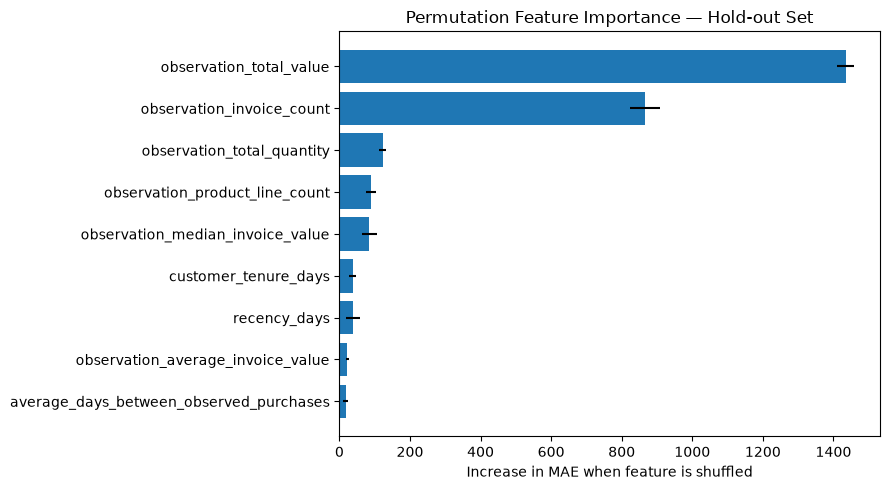

In [3]:
perm = permutation_importance(
    final_model, X_test, y_test,
    scoring="neg_mean_absolute_error",
    n_repeats=10, random_state=42, n_jobs=-1
)
importance_df = pd.DataFrame({
    "feature": feature_columns,
    "importance_mean_MAE_increase": perm.importances_mean,
    "importance_std": perm.importances_std,
}).sort_values("importance_mean_MAE_increase", ascending=False).reset_index(drop=True)
display(importance_df)

plt.figure(figsize=(9, 5))
plot_data = importance_df.sort_values("importance_mean_MAE_increase")
plt.barh(plot_data["feature"], plot_data["importance_mean_MAE_increase"], xerr=plot_data["importance_std"])
plt.xlabel("Increase in MAE when feature is shuffled")
plt.title("Permutation Feature Importance — Hold-out Set")
plt.tight_layout()
plt.show()

## 4. Residual and high-value customer analysis
Inspect whether the model systematically underpredicts large values. These diagnostics are important because the target is strongly right-skewed.

,actual_value_band,customers,mean_actual,mean_predicted,MAE
0,Zero,318,0.000000,564.254260,564.254260
1,"(0, 500]",171,269.239766,560.081577,324.737554
2,"(500, 2,000]",204,1057.386422,1151.174615,703.470882
3,"(2,000, 10,000]",142,3947.618944,3241.670968,2222.453430
4,"> 10,000",19,31459.372632,25294.194093,14413.549595


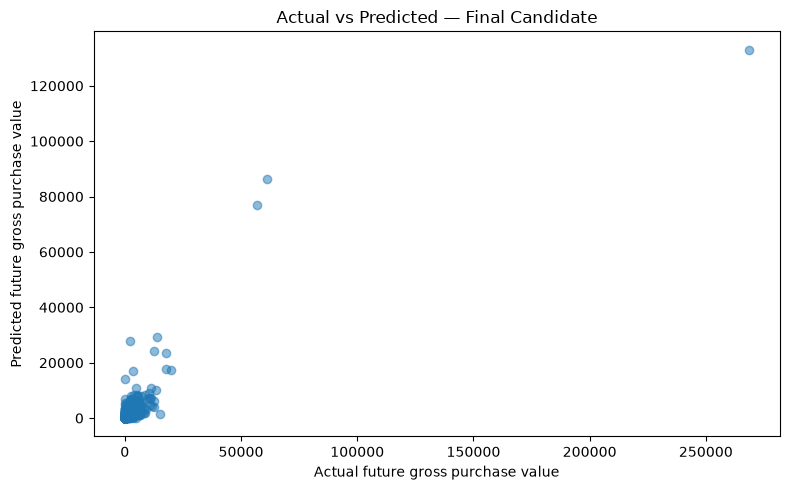

Mean signed error (actual - predicted): -36.2
Positive means average underprediction; negative means average overprediction.


In [4]:
diagnostics = pd.DataFrame({
    "actual": y_test.to_numpy(),
    "predicted": pred,
})
diagnostics["error"] = diagnostics["actual"] - diagnostics["predicted"]
diagnostics["absolute_error"] = diagnostics["error"].abs()
diagnostics["actual_value_band"] = pd.cut(
    diagnostics["actual"],
    bins=[-0.01, 0, 500, 2000, 10000, np.inf],
    labels=["Zero", "(0, 500]", "(500, 2,000]", "(2,000, 10,000]", "> 10,000"],
    include_lowest=True
)
band_summary = diagnostics.groupby("actual_value_band", observed=False).agg(
    customers=("actual", "size"),
    mean_actual=("actual", "mean"),
    mean_predicted=("predicted", "mean"),
    MAE=("absolute_error", "mean"),
).reset_index()
display(band_summary)

plt.figure(figsize=(8, 5))
plt.scatter(diagnostics["actual"], diagnostics["predicted"], alpha=0.5)
plt.xlabel("Actual future gross purchase value")
plt.ylabel("Predicted future gross purchase value")
plt.title("Actual vs Predicted — Final Candidate")
plt.tight_layout()
plt.show()

print("Mean signed error (actual - predicted):", round(diagnostics["error"].mean(), 2))
print("Positive means average underprediction; negative means average overprediction.")

## 5. Save backend model files and evaluation reports and evaluation evidence
The saved pipeline includes the imputer and model. Save locally under this model's own artifacts directory.

In [5]:
# Save deployable model files in the backend model directory.
# Keep experiment/evaluation reports within Model 03, not inside backend/models.
BACKEND_MODEL_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

MODEL_PATH = BACKEND_MODEL_DIR / "clv_random_forest_pipeline.joblib"
METADATA_PATH = BACKEND_MODEL_DIR / "clv_model_metadata.json"

joblib.dump(final_model, MODEL_PATH)
final_metrics.to_csv(REPORT_DIR / "clv_final_model_metrics.csv", index=False)
importance_df.to_csv(REPORT_DIR / "clv_permutation_importance.csv", index=False)
band_summary.to_csv(REPORT_DIR / "clv_final_model_value_band_analysis.csv", index=False)

metadata = {
    "model_name": "Random Forest Regressor",
    "status": "provisional; temporal backtesting still recommended",
    "target": TARGET,
    "target_interpretation": "future gross purchase value over fixed one-year prediction horizon; not true lifetime value or profit",
    "observation_window": {"start": "2009-12-01", "end": "2010-11-30"},
    "prediction_window": {"start": "2010-12-01", "end": "2011-11-30"},
    "prediction_postprocessing": "clip raw model predictions at zero; mirror this in the API layer",
    "features": feature_columns,
    "split": {"method": "train_test_split across customers", "test_size": 0.20, "random_state": 42},
    "metrics": {
        "MAE": float(final_metrics.loc[0, "MAE"]),
        "RMSE": float(final_metrics.loc[0, "RMSE"]),
        "R2": float(final_metrics.loc[0, "R2"]),
    },
    "python_sklearn_version": {"python": platform.python_version(), "scikit_learn": sklearn.__version__},
    "created_utc": datetime.now(timezone.utc).isoformat(),
}
with open(METADATA_PATH, "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=2)

print("Saved model pipeline:", MODEL_PATH)
print("Saved model metadata:", METADATA_PATH)
print("Saved evaluation reports:", REPORT_DIR)

Saved model pipeline: d:\MCA PU\Semesters\Semester 3\MCA_Projects\the-enterprise-ai-decision-intelligence-platform\backend\models\customer_lifetime_value\clv_random_forest_pipeline.joblib
Saved model metadata: d:\MCA PU\Semesters\Semester 3\MCA_Projects\the-enterprise-ai-decision-intelligence-platform\backend\models\customer_lifetime_value\clv_model_metadata.json
Saved evaluation reports: d:\MCA PU\Semesters\Semester 3\MCA_Projects\the-enterprise-ai-decision-intelligence-platform\ml\model_03_customer_lifetime_value\reports


## 6. Final review notes

- Random Forest is provisional because it achieved the lowest MAE in the current hold-out comparison; Ridge achieved lower RMSE and higher R².
- Review permutation importance and value-band errors before describing feature drivers.
- Feature importance is predictive association, not causal explanation.
- The split is not a temporal backtest. Before production claims, evaluate a second historical observation/target split if data coverage allows.
- Do not describe the target as true lifetime value or profit.
- Backend integration should load the saved pipeline, use the exact feature names/order listed in metadata, and clip predictions at zero.